# Bridge Element-Level HI Forecasting with Temporal GNN
This notebook builds a static bridge–element graph from the CSV, creates yearly feature snapshots (2020–2024), trains a Temporal GCN+GRU model to predict next-year element HI, and produces 5-year forecasts (2025–2029) with:
- **Autoregressive HI** feedback (`HI_prev`)
- **Scenario-based** evolution of bridge age, traffic, and weather covariates.

Outputs:
- `element_hi_forecast_2025_2029_AR_scenario.csv`


## 0) Setup
Make sure you have `torch`, `torch_geometric`, and their dependencies installed in the same kernel.
If imports fail, install PyTorch first, then install PyG matching your torch version.

In [85]:
import pandas as pd
import numpy as np

# ---- paths ----
CSV_PATH = "NEW_NBE_and_NBI_FL.csv"  # update if needed

# ---- column names ----
TARGET_COL = "HI"
YEAR_COL = "YEAR"
BRIDGE_ID_COL = "STRUCTURE_NUMBER"
ELEM_NUM_COL = "ELEMENT_NUMBER"
PARENT_ELEM_NUM_COL = "PARENT_ELEMENT_NUMBER"

YEARS = [2020, 2021, 2022, 2023, 2024]


## 1) Graph + snapshot builders
These functions:
- create global node indices for bridge and element nodes
- build static edges (bridge↔element, parent↔child)
- one-hot encode categorical columns
- **coerce to numeric and impute missing/infinite values** (critical to avoid NaNs in GNN)
- build yearly feature matrices `X_t` and labels `y_t`.


In [ ]:
from sklearn.feature_extraction import FeatureHasher
import hashlib

def normalize_bridge_id(x) -> str:
    """Ensure STRUCTURE_NUMBER becomes a stable string (avoid float formatting)."""
    if pd.isna(x):
        return None
    try:
        return str(int(float(x)))
    except Exception:
        return str(x)

def build_global_node_index(df: pd.DataFrame):
    bridge_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id)
    elem_nums = df[ELEM_NUM_COL].astype("Int64")

    bridge_nodes = set(f"bridge:{bid}" for bid in bridge_ids.dropna().unique())
    elem_nodes = set(
        f"elem:{bid}:{int(en)}"
        for bid, en in zip(bridge_ids, elem_nums)
        if (bid is not None) and (not pd.isna(en))
    )

    all_nodes = sorted(list(bridge_nodes | elem_nodes))
    node2idx = {k: i for i, k in enumerate(all_nodes)}
    return node2idx, all_nodes, elem_nodes, bridge_nodes

def build_static_edges(df: pd.DataFrame, node2idx: dict):
    edges = []
    b_ids = df[BRIDGE_ID_COL].map(normalize_bridge_id).values
    e_nums = df[ELEM_NUM_COL].astype("Int64").values
    p_nums = df[PARENT_ELEM_NUM_COL].astype("Int64").values if PARENT_ELEM_NUM_COL in df.columns else [pd.NA]*len(df)

    for bid, en, pn in zip(b_ids, e_nums, p_nums):
        if bid is None or pd.isna(en):
            continue

        b_key = f"bridge:{bid}"
        e_key = f"elem:{bid}:{int(en)}"

        if b_key in node2idx and e_key in node2idx:
            b_i = node2idx[b_key]
            e_i = node2idx[e_key]
            edges.append((b_i, e_i))
            edges.append((e_i, b_i))

        if (pn is not None) and (not pd.isna(pn)):
            p_key = f"elem:{bid}:{int(pn)}"
            if p_key in node2idx and e_key in node2idx:
                p_i = node2idx[p_key]
                e_i = node2idx[e_key]
                edges.append((p_i, e_i))
                edges.append((e_i, p_i))

    edges = list(set(edges))
    edge_index = np.array(edges, dtype=np.int64).T
    return edge_index

def hash_categorical_features(df: pd.DataFrame, n_features: int = 128):
    """
    Replace one-hot encoding with feature hashing to reduce memory.
    Maps each categorical feature to a fixed number of hash buckets.
    
    Parameters:
    -----------
    n_features : Fixed number of hash dimensions per feature (default 128)
                 Adjust based on dataset size and memory constraints.
    """
    work = df.copy()

    # bool -> int
    bool_cols = [c for c in work.columns if work[c].dtype == bool]
    for c in bool_cols:
        work[c] = work[c].astype(np.int8)

    # Don't hash IDs
    id_like = {
        YEAR_COL, BRIDGE_ID_COL,
        "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"
    }
    obj_cols = [c for c in work.columns if work[c].dtype == "object" and c not in id_like]

    # Drop ID columns early
    drop_cols = [c for c in list(id_like) if c in work.columns]
    work = work.drop(columns=drop_cols, errors="ignore")

    # Hash each categorical column independently
    hash_features = []
    for col in obj_cols:
        col_name = col
        # Convert to string, handle NaN
        col_values = work[col].fillna("__NA__").astype(str).values
        
        # Create hash-based features: hash each value to range [0, n_features)
        hashed = np.zeros((len(col_values), n_features), dtype=np.float32)
        for i, val in enumerate(col_values):
            # Use hash to determine which buckets activate for this value
            h = int(hashlib.md5(f"{col_name}_{val}".encode()).hexdigest(), 16)
            for j in range(n_features):
                # Multiple hash outputs populate different buckets
                bucket = (h + j) % n_features
                hashed[i, bucket] += 1.0 / (n_features // 4)  # Normalize contribution
        
        hash_features.append(hashed)
    
    # Concatenate all hash features
    if hash_features:
        X_hashed = np.concatenate(hash_features, axis=1)
    else:
        X_hashed = np.zeros((len(work), 0), dtype=np.float32)
    
    # Get numeric columns (excluding the ones we already dropped)
    numeric_cols = [c for c in work.select_dtypes(include=[np.number]).columns]
    X_numeric = work[numeric_cols].values.astype(np.float32)
    
    # Combine numeric + hashed features
    work_final = np.concatenate([X_numeric, X_hashed], axis=1)
    work_final = np.nan_to_num(work_final, nan=0.0)
    work_final = np.where(np.isinf(work_final), 0.0, work_final)
    
    feature_names = numeric_cols + [f"hash_{i}" for i in range(X_hashed.shape[1])]
    
    return pd.DataFrame(work_final, columns=feature_names)

def make_feature_frame(df: pd.DataFrame):
    """
    Process features using hashing instead of one-hot encoding.
    Much more memory-efficient for large datasets.
    """
    # Use hashing with 128 buckets per categorical feature
    # Adjust n_features DOWN if still OOM (try 64, 32)
    # or UP if you have room and want more capacity
    return hash_categorical_features(df, n_features=128)

def build_yearly_matrices(df_raw: pd.DataFrame, node2idx: dict):
    df = df_raw.copy()
    df[BRIDGE_ID_COL] = df[BRIDGE_ID_COL].map(normalize_bridge_id)

    feat_df = make_feature_frame(df)

    drop_cols = [
        TARGET_COL, YEAR_COL, BRIDGE_ID_COL,
        "LATEST_STRUCTURE_NUMBER", "NBI_8 - Structure Number", "NBI_2025 NBI Structure Number"
    ]
    drop_cols = [c for c in drop_cols if c in feat_df.columns]
    feat_df_no_leak = feat_df.drop(columns=drop_cols, errors="ignore")

    feature_cols = list(feat_df_no_leak.columns)
    N = len(node2idx)
    F = len(feature_cols)

    # Node type indicator
    node_type = np.zeros((N, 2), dtype=np.float32)  # [is_bridge, is_element]
    for k, i in node2idx.items():
        if k.startswith("bridge:"):
            node_type[i, 0] = 1.0
        else:
            node_type[i, 1] = 1.0

    X_list, y_list, mask_list = [], [], []

    for year in YEARS:
        sub_raw = df[df[YEAR_COL] == year]
        sub_feat = feat_df_no_leak.loc[sub_raw.index]

        X = np.zeros((N, F + 2), dtype=np.float32)
        y = np.full((N,), np.nan, dtype=np.float32)

        # Element node features + labels
        for ridx, row in sub_raw.iterrows():
            bid = row[BRIDGE_ID_COL]
            en = row[ELEM_NUM_COL]
            if (bid is None) or pd.isna(en):
                continue

            e_key = f"elem:{bid}:{int(en)}"
            if e_key not in node2idx:
                continue
            ni = node2idx[e_key]

            X[ni, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)
            y[ni] = float(row[TARGET_COL]) if (TARGET_COL in sub_raw.columns and not pd.isna(row[TARGET_COL])) else np.nan

        # Bridge node features: use first row per bridge-year
        first_per_bridge = sub_raw.dropna(subset=[BRIDGE_ID_COL]).groupby(BRIDGE_ID_COL).head(1)
        for ridx, row in first_per_bridge.iterrows():
            bid = row[BRIDGE_ID_COL]
            b_key = f"bridge:{bid}"
            if b_key not in node2idx:
                continue
            bi = node2idx[b_key]
            X[bi, :F] = sub_feat.loc[ridx].to_numpy(dtype=np.float32, copy=False)

        X[:, F:] = node_type
        mask = ~np.isnan(y)

        X_list.append(X)
        y_list.append(y)
        mask_list.append(mask)

    return X_list, y_list, mask_list, feature_cols

## 2) Build graph + snapshots (2020–2024)

In [87]:
# Load CSV (low_memory=False helps avoid mixed-type parsing issues)
df_raw = pd.read_csv(CSV_PATH, low_memory=False)

node2idx, idx2node, elem_nodes, bridge_nodes = build_global_node_index(df_raw)
edge_index = build_static_edges(df_raw, node2idx)

X_list, y_list, mask_list, feature_cols = build_yearly_matrices(df_raw, node2idx)

print("Nodes:", len(node2idx), "Edges:", edge_index.shape[1])
print("Snapshots:", len(X_list), "X0:", X_list[0].shape, "labels0:", int(mask_list[0].sum()))

# quick NaN/inf sanity check
for t, year in enumerate(YEARS):
    X = X_list[t]
    print(f"Year {year}: X NaNs={np.isnan(X).sum()} X infs={np.isinf(X).sum()} labeled={int(mask_list[t].sum())}")


MemoryError: Unable to allocate 1.03 GiB for an array with shape (211385, 5243) and data type bool

## 3) Add autoregressive feature `HI_prev`
We append one feature column to each snapshot representing last-known HI (normalized to 0..1).
During forecasting, we overwrite this feature each year with the model’s own prediction.

In [21]:
def add_hi_prev_feature(X_list, y_list):
    X_ar = []
    for t in range(len(X_list)):
        X = X_list[t]
        hi_prev = np.nan_to_num(y_list[t].copy(), nan=0.0).astype(np.float32)
        hi_prev_norm = (hi_prev / 100.0).astype(np.float32)
        X_new = np.concatenate([X, hi_prev_norm[:, None]], axis=1)
        X_ar.append(X_new)
    return X_ar

X_list_ar = add_hi_prev_feature(X_list, y_list)
print("Feature dim:", X_list[0].shape[1], "->", X_list_ar[0].shape[1])


Feature dim: 4700 -> 4701


## 4) Temporal GNN model (GCN + GRU) with sigmoid output
We predict normalized HI in 0..1 with a sigmoid, then convert back to 0..100 for reporting.

In [63]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import GCNConv

class TemporalGCN_GRU_DeltaMonotonic(nn.Module):
    def __init__(self, in_dim: int, gcn_hidden: int = 128, gru_hidden: int = 128,
                 max_drop=0.15):
        super().__init__()
        self.gcn1 = GCNConv(in_dim, gcn_hidden)
        self.gcn2 = GCNConv(gcn_hidden, gcn_hidden)
        self.gru = nn.GRU(input_size=gcn_hidden, hidden_size=gru_hidden, batch_first=False)
        self.delta_head = nn.Linear(gru_hidden, 1)
        self.max_drop = max_drop

    def forward(self, X_seq, edge_index):
        embeddings = []
        for X in X_seq:
            h = F.relu(self.gcn1(X, edge_index))
            h = F.relu(self.gcn2(h, edge_index))
            embeddings.append(h)

        H = torch.stack(embeddings, dim=0)   # (T, N, H)
        out, _ = self.gru(H)                 # (T, N, H)

        raw = self.delta_head(out).squeeze(-1)   # (T, N)

        # HI_prev is the last feature column
        hi_prev_seq = torch.stack([X[:, -1] for X in X_seq], dim=0)  # (T, N)

        # State-dependent monotonic deterioration:
        # if HI is already low, yearly drop becomes smaller
        delta = -torch.sigmoid(raw) * self.max_drop * hi_prev_seq

        hi_next = hi_prev_seq + delta
        hi_next = torch.clamp(hi_next, 0.0, 1.0)

        return hi_next[:-1], delta[:-1]


## 5) Train/test split (temporal)
- Train on: 2020→2021, 2021→2022, 2022→2023
- Test on:  2023→2024


In [64]:
def train_delta_model(model, X_list, y_list, mask_list, edge_index, lr=1e-3, epochs=120,
                      delta_loss_weight=0.3):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list]

    # normalize targets to 0..1
    y_seq = [torch.tensor(np.nan_to_num(y, nan=np.nan), dtype=torch.float32, device=device) / 100.0
             for y in y_list]
    m_seq = [torch.tensor(m, dtype=torch.bool, device=device) for m in mask_list]

    train_ts = [0, 1, 2]   # 2020->2021, 2021->2022, 2022->2023
    test_t = 3             # 2023->2024

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    for ep in range(1, epochs + 1):
        model.train()
        opt.zero_grad()

        pred_hi_next, pred_delta = model(X_seq, edge_index_t)

        train_losses = []
        for t in train_ts:
            mask = m_seq[t + 1]
            if mask.sum() == 0:
                continue

            y_true = y_seq[t + 1][mask]              # actual HI_next
            y_pred = pred_hi_next[t][mask]           # predicted HI_next

            hi_prev = X_seq[t][:, -1][mask]          # previous HI from input
            true_delta = y_true - hi_prev            # actual year-to-year delta
            pred_delta_t = pred_delta[t][mask]

            hi_loss = F.smooth_l1_loss(y_pred, y_true)
            delta_loss = F.smooth_l1_loss(pred_delta_t, true_delta)

            loss_t = hi_loss + delta_loss_weight * delta_loss
            train_losses.append(loss_t)

        loss = torch.stack(train_losses).mean()
        loss.backward()
        opt.step()

        if ep % 20 == 0:
            model.eval()
            with torch.no_grad():
                mask = m_seq[test_t + 1]
                y_true = y_seq[test_t + 1][mask]
                y_pred = pred_hi_next[test_t][mask]

                hi_prev = X_seq[test_t][:, -1][mask]
                true_delta = y_true - hi_prev
                pred_delta_t = pred_delta[test_t][mask]

                hi_loss = F.smooth_l1_loss(y_pred, y_true)
                delta_loss = F.smooth_l1_loss(pred_delta_t, true_delta)
                test_loss = hi_loss + delta_loss_weight * delta_loss

            print(
                f"epoch {ep:04d} | "
                f"train {loss.item():.5f} | "
                f"test {test_loss.item():.5f} | "
                f"test_hi {hi_loss.item():.5f} | "
                f"test_delta {delta_loss.item():.5f}"
            )

    return model

model_delta_mono = TemporalGCN_GRU_DeltaMonotonic(
    in_dim=X_list_ar[0].shape[1],
    gcn_hidden=64,
    gru_hidden=64,
    max_drop=0.15
)

model_delta_mono = train_delta_model(
    model=model_delta_mono,
    X_list=X_list_ar,
    y_list=y_list,
    mask_list=mask_list,
    edge_index=edge_index,
    lr=1e-3,
    epochs=120,
    delta_loss_weight=0.3
)

torch.save(model_delta_mono.state_dict(), "temporal_gnn_bridge_hi_delta_monotonic.pt")
print("Saved temporal_gnn_bridge_hi_delta_monotonic.pt")

epoch 0020 | train 0.02274 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
epoch 0040 | train 0.02273 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
epoch 0060 | train 0.02273 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
epoch 0080 | train 0.02273 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
epoch 0100 | train 0.02273 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
epoch 0120 | train 0.02273 | test 0.01106 | test_hi 0.00851 | test_delta 0.00851
Saved temporal_gnn_bridge_hi_delta_monotonic.pt


## 6) Evaluate held-out 2023→2024 prediction (MAE/RMSE in HI points)

===== Held-out Test Performance (2023 -> 2024) =====
MAE:              3.0821
RMSE:             13.0457
R2:               0.5380
Low-HI MAE < 70:  3.9077
Very-low HI < 50: 6.6086
Test samples:     20390

===== Summary Table =====


,Metric,Value
0,MAE,3.082070
1,RMSE,13.045742
2,R2,0.538032
3,Low-HI MAE (<70),3.907685
4,Very-low-HI MAE (<50),6.608594
5,Test Samples,20390.000000


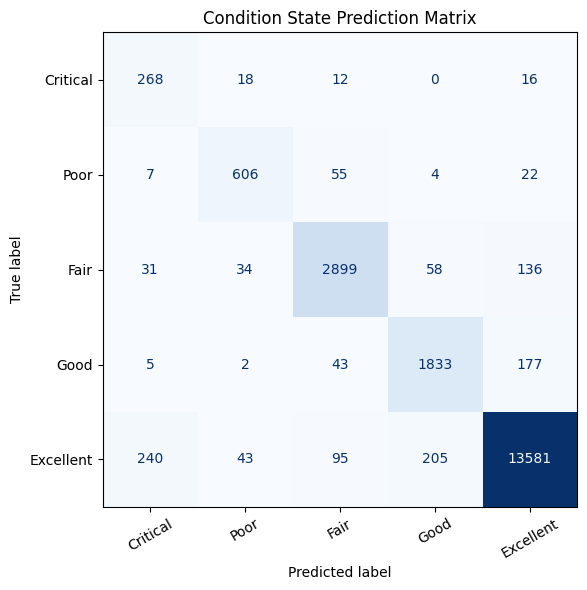


===== Condition State Confusion Matrix =====


,Pred: Critical,Pred: Poor,Pred: Fair,Pred: Good,Pred: Excellent
Actual: Critical,268,18,12,0,16
Actual: Poor,7,606,55,4,22
Actual: Fair,31,34,2899,58,136
Actual: Good,5,2,43,1833,177
Actual: Excellent,240,43,95,205,13581


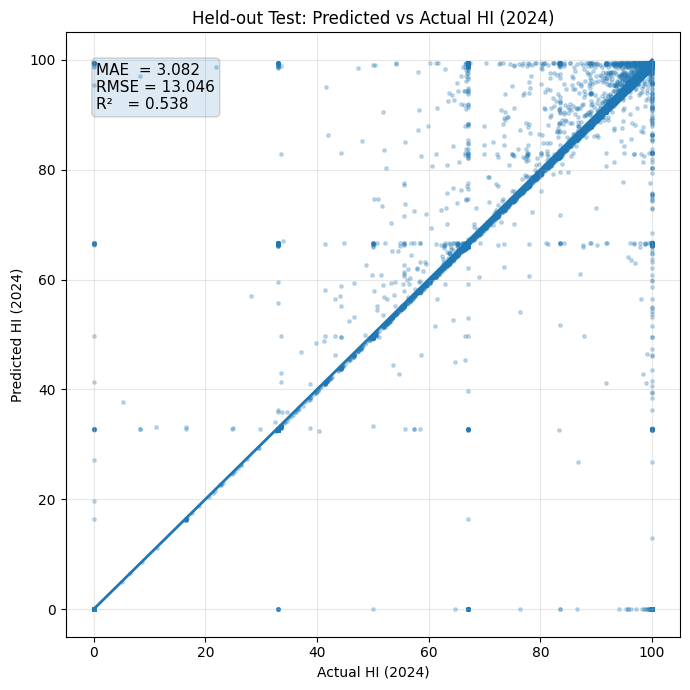

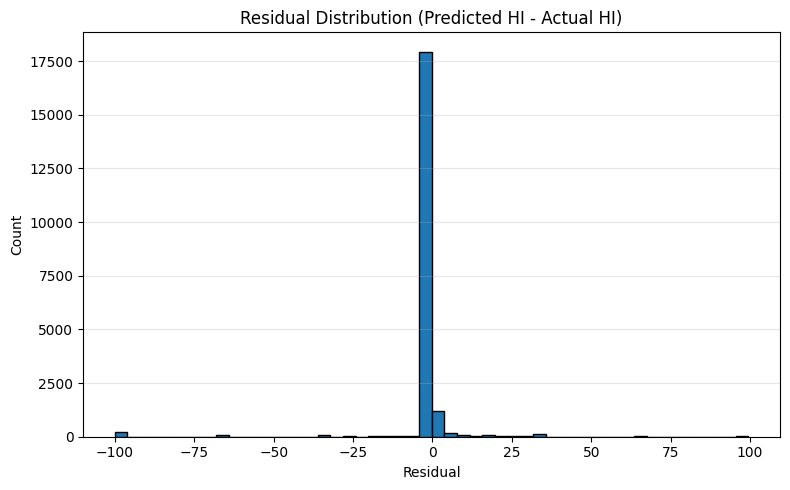

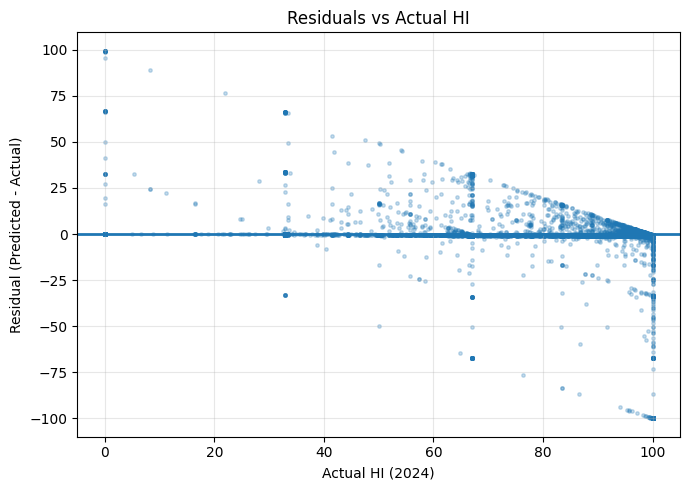

In [68]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

# ------------------------------------------------------------
# Evaluate held-out test transition: 2023 -> 2024
# Assumes:
#   - model_delta_mono is already trained
#   - X_list_ar, y_list, mask_list, edge_index exist
# ------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_delta_mono = model_delta_mono.to(device).eval()

edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)
X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]

with torch.no_grad():
    # pred_hi_next is normalized to 0..1, so convert back to 0..100
    pred_hi_next, pred_delta = model_delta_mono(X_seq, edge_index_t)
    pred_2024 = pred_hi_next[3].detach().cpu().numpy() * 100.0   # 2023 -> 2024

true_2024 = y_list[4]
mask_2024 = mask_list[4]

yhat = pred_2024[mask_2024]
ytrue = true_2024[mask_2024]

# ------------------------------------------------------------
# Core regression metrics
# ------------------------------------------------------------
mae = mean_absolute_error(ytrue, yhat)
rmse = np.sqrt(mean_squared_error(ytrue, yhat))
r2 = r2_score(ytrue, yhat)

low_mask = ytrue < 70
very_low_mask = ytrue < 50

low_mae = mean_absolute_error(ytrue[low_mask], yhat[low_mask]) if low_mask.sum() > 0 else np.nan
very_low_mae = mean_absolute_error(ytrue[very_low_mask], yhat[very_low_mask]) if very_low_mask.sum() > 0 else np.nan

print("===== Held-out Test Performance (2023 -> 2024) =====")
print(f"MAE:              {mae:.4f}")
print(f"RMSE:             {rmse:.4f}")
print(f"R2:               {r2:.4f}")
print(f"Low-HI MAE < 70:  {low_mae:.4f}")
print(f"Very-low HI < 50: {very_low_mae:.4f}")
print(f"Test samples:     {len(ytrue)}")

# ------------------------------------------------------------
# Summary table for presentation/report
# ------------------------------------------------------------
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R2", "Low-HI MAE (<70)", "Very-low-HI MAE (<50)", "Test Samples"],
    "Value": [mae, rmse, r2, low_mae, very_low_mae, len(ytrue)]
})

print("\n===== Summary Table =====")
display(metrics_df)

# ------------------------------------------------------------
# Condition-state confusion matrix
# Engineers often find this easier to interpret than raw regression metrics
# ------------------------------------------------------------
bins = [0, 30, 50, 70, 90, 100.0001]
labels = ["Critical", "Poor", "Fair", "Good", "Excellent"]

true_cat = pd.cut(ytrue, bins=bins, labels=labels, include_lowest=True)
pred_cat = pd.cut(yhat, bins=bins, labels=labels, include_lowest=True)

cm = confusion_matrix(true_cat, pred_cat, labels=labels)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Condition State Prediction Matrix")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Also show the confusion matrix as a dataframe
cm_df = pd.DataFrame(cm, index=[f"Actual: {x}" for x in labels], columns=[f"Pred: {x}" for x in labels])
print("\n===== Condition State Confusion Matrix =====")
display(cm_df)

# ------------------------------------------------------------
# Scatter plot: Actual vs Predicted
# ------------------------------------------------------------
plt.figure(figsize=(7, 7))
plt.scatter(ytrue, yhat, s=6, alpha=0.25)

lo = min(ytrue.min(), yhat.min())
hi = max(ytrue.max(), yhat.max())
plt.plot([lo, hi], [lo, hi], linewidth=2)

plt.title("Held-out Test: Predicted vs Actual HI (2024)")
plt.xlabel("Actual HI (2024)")
plt.ylabel("Predicted HI (2024)")
plt.grid(True, alpha=0.3)

# Put metrics directly on plot for presentation use
textstr = "\n".join([
    f"MAE  = {mae:.3f}",
    f"RMSE = {rmse:.3f}",
    f"R²   = {r2:.3f}"
])
plt.text(
    0.05, 0.95, textstr,
    transform=plt.gca().transAxes,
    fontsize=11,
    verticalalignment="top",
    bbox=dict(boxstyle="round", alpha=0.15)
)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Residual analysis
# residual = prediction - truth
# ------------------------------------------------------------
residuals = yhat - ytrue

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=50, edgecolor="black")
plt.title("Residual Distribution (Predicted HI - Actual HI)")
plt.xlabel("Residual")
plt.ylabel("Count")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Optional: residuals vs actual
# Helps detect bias at low or high HI ranges
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
plt.scatter(ytrue, residuals, s=6, alpha=0.25)
plt.axhline(0, linewidth=2)
plt.title("Residuals vs Actual HI")
plt.xlabel("Actual HI (2024)")
plt.ylabel("Residual (Predicted - Actual)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 7) Scenario-based autoregressive rollout (2025–2029)
We update these covariates each future year:
- **NBI Bridge Age:** +1 each year
- **ADT / traffic:** multiplicative growth (scenario)
- **Weather fields:** linear or % trends (scenario)
and we also update `HI_prev` with the model’s predicted HI.


In [47]:
from collections import defaultdict

def build_bridge_to_node_indices(node2idx):
    bridge_to_nodes = defaultdict(list)
    for k, i in node2idx.items():
        if k.startswith("bridge:"):
            bid = k.split(":")[1]
            bridge_to_nodes[bid].append(i)
        elif k.startswith("elem:"):
            _, bid, _en = k.split(":")
            bridge_to_nodes[bid].append(i)
    return bridge_to_nodes

bridge_to_nodes = build_bridge_to_node_indices(node2idx)

COVAR_NAMES = [
    "NBI_Bridge Age (yr)",
    "NBI_29 - Average Daily Traffic",
    "NBI_Average Temperature",
    "NBI_Maximum Temperature",
    "NBI_Minimum Temperature",
    "NBI_Number of Freeze-Thaw Cycles",
    "NBI_Number of Days with Measurable Precipitation",
    "NBI_Number of Days with Temperature Below 0?C",
    "NBI_Number of Snowfall Days",
    "NBI_Total Precipitation"
]

def find_feature_index(feature_cols, name):
    return feature_cols.index(name) if name in feature_cols else None

covar_idx = {}
missing = []
for nm in COVAR_NAMES:
    ix = find_feature_index(feature_cols, nm)
    if ix is None:
        missing.append(nm)
    else:
        covar_idx[nm] = ix

print("Found covariates:", list(covar_idx.keys()))
if missing:
    print("Missing (check column spelling):", missing)


Found covariates: ['NBI_Bridge Age (yr)', 'NBI_29 - Average Daily Traffic', 'NBI_Average Temperature', 'NBI_Maximum Temperature', 'NBI_Minimum Temperature', 'NBI_Number of Freeze-Thaw Cycles', 'NBI_Number of Days with Measurable Precipitation', 'NBI_Number of Days with Temperature Below 0?C', 'NBI_Number of Snowfall Days', 'NBI_Total Precipitation']


In [48]:
def apply_scenario_updates(X, year_step, covar_idx, bridge_to_nodes, scenario):
    def upd(rows, col, vals):
        X[rows, col] = vals

    adt_growth = scenario.get("adt_growth", 0.02)
    temp_trend = scenario.get("temp_trend_c_per_year", 0.15)
    wind_trend = scenario.get("wind_trend_per_year", 0.0)
    precip_trend_pct = scenario.get("precip_trend_pct_per_year", 0.01)
    freeze_thaw_trend_pct = scenario.get("freeze_thaw_trend_pct_per_year", -0.005)
    below0_trend_pct = scenario.get("below0_days_trend_pct_per_year", -0.01)
    snowfall_trend_pct = scenario.get("snowfall_days_trend_pct_per_year", -0.01)
    precip_days_trend_pct = scenario.get("precip_days_trend_pct_per_year", 0.00)

    for bid, rows in bridge_to_nodes.items():
        rows = np.array(rows, dtype=int)

        if "NBI Bridge Age" in covar_idx:
            c = covar_idx["NBI Bridge Age"]
            upd(rows, c, X[rows, c] + 1.0)

        if "NBI_29 - Average Daily Traffic" in covar_idx:
            c = covar_idx["NBI_29 - Average Daily Traffic"]
            upd(rows, c, X[rows, c] * (1.0 + adt_growth))

        for nm in ["NBI_Avg Daily Max Temp", "NBI_Avg Daily Min Temp",
                   "NBI_Avg Monthly Max Temp", "NBI_Avg Monthly Min Temp"]:
            if nm in covar_idx:
                c = covar_idx[nm]
                upd(rows, c, X[rows, c] + temp_trend)

        if "NBI_Avg Daily Wind Speed" in covar_idx:
            c = covar_idx["NBI_Avg Daily Wind Speed"]
            upd(rows, c, X[rows, c] + wind_trend)

        if "NBI_Freeze Thaw Cycles" in covar_idx:
            c = covar_idx["NBI_Freeze Thaw Cycles"]
            upd(rows, c, X[rows, c] * (1.0 + freeze_thaw_trend_pct))

        if "NBI_Number of Days with Measurable Precipitation" in covar_idx:
            c = covar_idx["NBI_Number of Days with Measurable Precipitation"]
            upd(rows, c, X[rows, c] * (1.0 + precip_days_trend_pct))

        if "NBI_Number of Days with Temperature Below 0C" in covar_idx:
            c = covar_idx["NBI_Number of Days with Temperature Below 0C"]
            upd(rows, c, X[rows, c] * (1.0 + below0_trend_pct))

        if "NBI_Number of Snowfall Days" in covar_idx:
            c = covar_idx["NBI_Number of Snowfall Days"]
            upd(rows, c, X[rows, c] * (1.0 + snowfall_trend_pct))

        if "NBI_Total Precipitation" in covar_idx:
            c = covar_idx["NBI_Total Precipitation"]
            upd(rows, c, X[rows, c] * (1.0 + precip_trend_pct))

    return X

import torch

@torch.no_grad()
def rollout_autoregressive_with_covariates_delta(model, X_list_ar, edge_index, years_ahead,
                                                 covar_idx, bridge_to_nodes, scenario):
    device = next(model.parameters()).device
    edge_index_t = torch.tensor(edge_index, dtype=torch.long, device=device)

    # historical sequence
    X_seq = [torch.tensor(X, dtype=torch.float32, device=device) for X in X_list_ar]
    last_X = X_seq[-1].clone()

    preds_future = []

    for step in range(1, years_ahead + 1):
        pred_hi_next, pred_delta = model(X_seq, edge_index_t)

        # predicted next HI in normalized space
        y_hat_next = pred_hi_next[-1]

        # save as real HI (0..100)
        preds_future.append((y_hat_next * 100.0).detach().cpu().numpy())

        # convert last snapshot to numpy for covariate updates
        last_np = last_X.detach().cpu().numpy()

        # update HI_prev feature (last column)
        last_np[:, -1] = y_hat_next.detach().cpu().numpy()

        # update age, traffic, weather according to scenario
        last_np = apply_scenario_updates(last_np, step, covar_idx, bridge_to_nodes, scenario)

        # rebuild torch tensor
        last_X = torch.tensor(last_np, dtype=torch.float32, device=device)

        # slide the sequence window forward
        X_seq = X_seq[1:] + [last_X.clone()]

    return preds_future

In [69]:
scenario = {
    "adt_growth": 0.02,
    "temp_trend_c_per_year": 0.15,
    "precip_trend_pct_per_year": 0.01,
    "freeze_thaw_trend_pct_per_year": -0.005,
    "below0_days_trend_pct_per_year": -0.01,
    "snowfall_trend_pct_per_year": -0.01
}

preds_future = rollout_autoregressive_with_covariates_delta(
    model=model_delta_mono,
    X_list_ar=X_list_ar,
    edge_index=edge_index,
    years_ahead=5,
    covar_idx=covar_idx,
    bridge_to_nodes=bridge_to_nodes,
    scenario=scenario
)

elem_rows = []
for node_key, idx in node2idx.items():
    if node_key.startswith("elem:"):
        _, bid, en = node_key.split(":")
        elem_rows.append((idx, bid, int(en)))

out = pd.DataFrame(elem_rows, columns=["node_idx", "STRUCTURE_NUMBER", "ELEMENT_NUMBER"])

for i, year in enumerate([2025, 2026, 2027, 2028, 2029]):
    out[f"HI_pred_{year}"] = preds_future[i][out["node_idx"].to_numpy()]

out.to_csv("element_hi_forecast_2025_2029_delta_monotonic_scenario.csv", index=False)
print("Saved element_hi_forecast_2025_2029_delta_monotonic_scenario.csv")
out.head()


Saved element_hi_forecast_2025_2029_delta_monotonic_scenario.csv


,node_idx,STRUCTURE_NUMBER,ELEMENT_NUMBER,HI_pred_2025,HI_pred_2026,HI_pred_2027,HI_pred_2028,HI_pred_2029
0,3128,103420000000000,109,95.746574,95.746574,95.216103,95.216103,94.688568
1,3129,103420000000000,110,94.185272,94.185272,93.663445,93.663445,93.144516
2,3130,103420000000000,12,32.817169,32.817169,32.635353,32.635353,32.454540
3,3131,103420000000000,202,0.000000,0.000000,0.000000,0.000000,0.000000
4,3132,103420000000000,205,97.069206,97.069206,96.531403,96.531403,95.996582


## 8) Plotting
Bridge-level element trajectories + worst/median, and portfolio histogram.

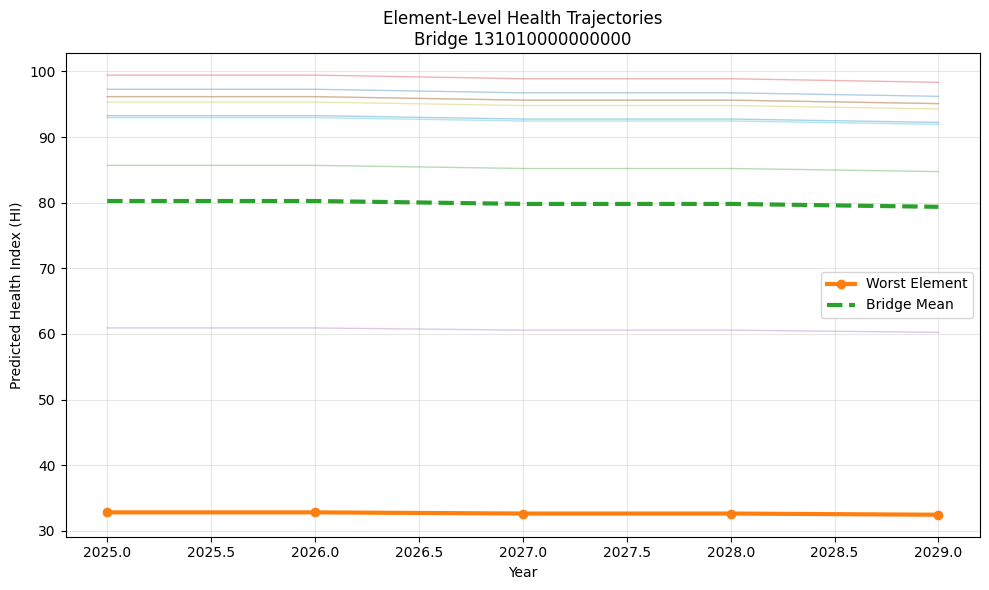

In [75]:
import matplotlib.pyplot as plt
import numpy as np

years = np.array([2025, 2026, 2027, 2028, 2029])

# pick a bridge
bridge_id = out["STRUCTURE_NUMBER"].iloc[567]

# subset of that bridge
sub = out[out["STRUCTURE_NUMBER"] == bridge_id].copy()

plt.figure(figsize=(10,6))

# plot every element trajectory
for _, r in sub.iterrows():
    traj = [r[f"HI_pred_{y}"] for y in years]
    plt.plot(years, traj, alpha=0.35, linewidth=1)

# worst element trajectory
worst = [sub[f"HI_pred_{y}"].min() for y in years]
plt.plot(years, worst, linewidth=3, marker="o", label="Worst Element")

# bridge mean trajectory
mean_vals = [sub[f"HI_pred_{y}"].mean() for y in years]
plt.plot(years, mean_vals, linewidth=3, linestyle="--", label="Bridge Mean")

plt.title(f"Element-Level Health Trajectories\nBridge {bridge_id}")
plt.xlabel("Year")
plt.ylabel("Predicted Health Index (HI)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.show()


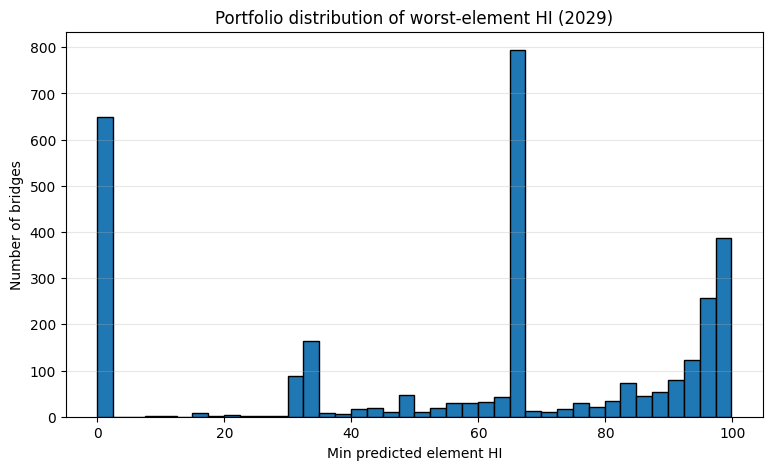

In [60]:
bridge_min_2029 = out.groupby("STRUCTURE_NUMBER")["HI_pred_2029"].min()

plt.figure(figsize=(9, 5))
plt.hist(bridge_min_2029, bins=40, edgecolor="black")
plt.title("Portfolio distribution of worst-element HI (2029)")
plt.xlabel("Min predicted element HI")
plt.ylabel("Number of bridges")
plt.grid(axis="y", alpha=0.3)
plt.show()
